# Opening range breakout

Research note on the one-minute Nasdaq-100 future. One contract. Targets and stops are index points, not premium. No filter beyond the open.

This notebook is the same test as the note: the verdict, both walk-forwards, the fold-by-fold choices, return attribution by quarter, year, and month, and all 64 cells. Figures are read from `data/orb_results.json`, which `research/orb_nq.py` writes from the tape.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data" / "orb_results.json").exists():
    ROOT = ROOT.parent
RES = json.loads((ROOT / "data" / "orb_results.json").read_text())
TAPE = ROOT / "data" / "Dataset_NQ_1min_2022_2025.csv"
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.2f}")

def money(n):
    sign = "−" if n < 0 else ""
    return f"{sign}${abs(n):,.0f}"

def signed(n, digits=1):
    if n is None:
        return "—"
    sign = "+" if n > 0 else ("−" if n < 0 else "")
    return sign + f"{abs(n):,.{digits}f}"

def pct(n, digits=1):
    if n is None:
        return "—"
    return signed(n, digits) + "%"

meta = RES["meta"]
print(meta["name"])
print(f"{meta['first_day']} → {meta['last_day']}")
print(f"sessions {meta['sessions']}  complete {meta['complete_sessions']}  early close {meta['early_close_sessions']}")
print(f"capital {money(meta['starting_equity'])}   point value ${meta['point_value']:.0f}   contracts {meta['contracts']}")
print(f"tape {TAPE.name}  exists {TAPE.exists()}  bytes {TAPE.stat().st_size:,}")


CME E-mini Nasdaq-100 futures
2022-12-27 → 2025-12-11
sessions 765  complete 729  early close 36
capital $100,000   point value $20   contracts 1
tape Dataset_NQ_1min_2022_2025.csv  exists True  bytes 72,522,264


## The cell the year table belongs to

The year table that ends at $222,220 is **OR 30 / target 150 / stop 150**. It is not the row above it.

OR 30 / target 150 / stop 200 is the best full-sample cell. It makes more points and finishes at a different equity. Both are below, with the check that the years compound back to the grid row.


In [2]:
def cell(or_, tp, sl):
    return next(g for g in RES["grid"] if g["or"] == or_ and g["tp"] == tp and g["sl"] == sl)

def show_summary(g):
    f = g["full"]
    print(
        f"OR {g['or']} / target {g['tp']} / stop {g['sl']}"
        f"   points {signed(f['net_points'], 2)}"
        f"   return {pct(f['return_pct'], 2)}"
        f"   Sharpe {f['sharpe']:.3f}"
        f"   max DD {f['max_dd_pct']:.2f}%"
        f"   win {f['win_rate']*100:.1f}%"
        f"   trades {f['trades']}"
        f"   end {money(f['end_equity'])}"
    )
    print(
        f"   holdout points {signed(g['oos']['net_points'], 2)}"
        f"   holdout return {pct(g['oos']['return_pct'], 2)}"
        f"   holdout Sharpe {g['oos']['sharpe']:.3f}"
        f"   train Sharpe {g['is']['sharpe']:.3f}"
    )

rows = []
for g in RES["grid"]:
    net = round(sum(r["net_usd"] for r in g["annual"]), 2)
    worst = max(r["max_dd_pct"] for r in g["annual"])
    end = g["annual"][-1]["end_equity"]
    rows.append({
        "or": g["or"], "target": g["tp"], "stop": g["sl"],
        "full_points": g["full"]["net_points"],
        "full_return_pct": g["full"]["return_pct"],
        "full_sharpe": g["full"]["sharpe"],
        "full_dd_pct": g["full"]["max_dd_pct"],
        "worst_year_dd_pct": worst,
        "annual_pnl_usd": net,
        "full_pnl_usd": g["full"]["net_usd"],
        "annual_end_equity": end,
        "full_end_equity": g["full"]["end_equity"],
        "pnl_matches": abs(net - g["full"]["net_usd"]) < 0.05,
        "equity_matches": abs(end - g["full"]["end_equity"]) < 0.05,
        "dd_covers_every_year": g["full"]["max_dd_pct"] + 0.02 >= worst,
    })
audit = pd.DataFrame(rows)
assert audit["pnl_matches"].all()
assert audit["equity_matches"].all()
assert audit["dd_covers_every_year"].all()

for spec in ((30, 150, 150), (30, 150, 200)):
    show_summary(cell(*spec))
    a = audit[(audit["or"] == spec[0]) & (audit["target"] == spec[1]) & (audit["stop"] == spec[2])].iloc[0]
    print(
        f"   years sum to ${a['annual_pnl_usd']:,.2f} against full-sample ${a['full_pnl_usd']:,.2f};"
        f" deepest year {a['worst_year_dd_pct']:.2f}% against full-sample {a['full_dd_pct']:.2f}%"
    )
print(f"all {len(audit)} cells: yearly dollars match the grid, and no year is a deeper percent drawdown than the full sample")


OR 30 / target 150 / stop 150   points +6,111.00   return +122.22%   Sharpe 1.249   max DD 20.14%   win 53.6%   trades 760   end $222,220
   holdout points +2,879.83   holdout return +57.60%   holdout Sharpe 1.296   train Sharpe 1.318
   years sum to $122,220.00 against full-sample $122,220.00; deepest year 20.14% against full-sample 20.14%
OR 30 / target 150 / stop 200   points +6,291.75   return +125.84%   Sharpe 1.213   max DD 21.42%   win 55.1%   trades 760   end $225,835
   holdout points +3,623.58   holdout return +72.47%   holdout Sharpe 1.508   train Sharpe 1.107
   years sum to $125,835.00 against full-sample $125,835.00; deepest year 21.42% against full-sample 21.42%
all 64 cells: yearly dollars match the grid, and no year is a deeper percent drawdown than the full sample


### Why the drawdown column used to contradict the year table

On OR 30 / target 150 / stop 150 the equity path is unchanged. The years still compound to $222,220, which is +6,111 points and +122.22%, the grid’s full-sample return.

The old full-sample drawdown was 14.7%. That was the percentage at the largest *dollar* loss, a 2025 dip on a much larger account. The 2023 row of the same cell was a 20.14% decline and about $22,500. The deeper percentage is the drawdown. It is now the number in both places.

OR 30 / target 150 / stop 200 had the same bug: the grid said 12.9% while 2023 on that path was 21.42%. The full-sample drawdown is now 21.42%.


In [3]:
def year_table(g):
    df = pd.DataFrame(g["annual"])[
        ["year", "strategy_return_pct", "bh_return_pct", "diff_pp", "start_equity", "end_equity",
         "trades", "win_rate", "max_dd_pct", "vol_ann_pct", "sharpe", "net_usd"]
    ].copy()
    df["win_rate"] = (df["win_rate"] * 100).round(1)
    return df

for spec in ((30, 150, 150), (30, 150, 200)):
    g = cell(*spec)
    display(Markdown(f"**OR {spec[0]} / target {spec[1]} / stop {spec[2]} — year**"))
    display(year_table(g))


**OR 30 / target 150 / stop 150 — year**

,year,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,net_usd
0,2022,4.1000,-0.6600,4.7600,"100,000.00","104,097.00",4,75.00,0.2900,NaN,NaN,"4,097.00"
1,2023,41.05,106.36,-65.31,"104,097.00","146,829.50",255,52.90,20.14,30.36,1.2630,"42,732.50"
2,2024,47.39,30.95,16.44,"146,829.50","216,418.50",258,55.40,10.00,19.79,2.0070,"69,589.00"
3,2025,2.6800,28.60,-25.92,"216,418.50","222,220.00",243,51.80,14.67,17.25,0.2440,"5,801.50"


**OR 30 / target 150 / stop 200 — year**

,year,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,net_usd
0,2022,4.1000,-0.6600,4.7600,"100,000.00","104,097.00",4,75.00,0.2900,NaN,NaN,"4,097.00"
1,2023,38.72,106.36,-67.64,"104,097.00","144,399.50",255,53.70,21.42,31.60,1.1740,"40,302.50"
2,2024,41.90,30.95,10.95,"144,399.50","204,908.50",258,56.20,11.35,21.77,1.6740,"60,509.00"
3,2025,10.21,28.60,-18.39,"204,908.50","225,835.00",243,55.10,12.93,18.60,0.6310,"20,926.50"


## The test that was not allowed to peek

Expanding walk-forward. Each quarter’s parameters are chosen on every session before that quarter, then left alone. The rolling book uses only the prior 252 sessions. Neither book is a row of the 64-cell grid.


In [4]:
exp = RES["wf_expanding"]["summary"]
roll = RES["wf_rolling"]["summary"]
exp_bh = RES["wf_expanding"]["bh_summary"]
roll_bh = RES["wf_rolling"]["bh_summary"]
pos_full = sum(g["full"]["net_points"] > 0 for g in RES["grid"])
pos_oos = sum(g["oos"]["net_points"] > 0 for g in RES["grid"])
best = max(RES["grid"], key=lambda g: g["full"]["net_points"])

verdict = f'''Expanding walk-forward finished at {money(exp["end_equity"])}. That is {signed(exp["net_points"], 0)} points, {pct(exp["return_pct"])} on the starting capital, Sharpe {exp["sharpe"]:.2f}, closed-trade drawdown {exp["max_dd_pct"]:.1f}%. Buy-and-hold of the same one contract, over the same out-of-sample window, made {signed(exp_bh["net_points"], 0)} points, {pct(exp_bh["return_pct"])}, Sharpe {exp_bh["sharpe"]:.2f}. Long breakouts in the walk-forward book made {signed(exp["long_points"], 0)} points. Shorts lost {signed(abs(exp["short_points"]), 0)} points. A rolling 252-session window, the robustness check, made {signed(roll["net_points"], 0)} points, Sharpe {roll["sharpe"]:.2f}, and still trailed the hold by a wide margin.

Friction is the whole edge. Gross of costs the expanding book is {signed(exp["gross_net_points"], 0)} points. Base friction (one tick and $4.50 round turn) leaves {signed(exp["net_points"], 0)}. Two ticks and $8 leaves {signed(exp["stress_net_points"], 0)}. {pos_full} of 64 cells are profitable on the full tape and {pos_oos} of 64 on the July 2024 holdout. That is one bull market counted sixty-four times. The best full-sample cell, OR {best["or"]} / target {best["tp"]} / stop {best["sl"]}, made {signed(best["full"]["net_points"], 0)} points in sample and {signed(best["oos"]["net_points"], 0)} on the holdout. The selection rule did not keep that cell, and the rule is the result.'''
display(Markdown(verdict))

kpis = pd.DataFrame([
    ["Walk-forward return", pct(exp["return_pct"]), money(exp["end_equity"])],
    ["Sharpe, rf = 0", f"{exp['sharpe']:.2f}", f"Vol {exp['vol_ann_pct']:.1f}%"],
    ["Max drawdown", pct(-exp["max_dd_pct"]), money(-exp["max_dd_usd"])],
    ["Buy and hold", pct(exp_bh["return_pct"]), f"{signed(exp_bh['net_points'], 0)} pts"],
    ["Difference", pct(exp["return_pct"] - exp_bh["return_pct"]), "percentage points"],
    ["Trades · win rate", f"{exp['trades']} · {exp['win_rate']*100:.1f}%",
     f"PF {exp['profit_factor']:.2f} · {exp['exits']['target']} target / {exp['exits']['stop']} stop / {exp['exits']['time']} time"],
    ["Rolling 252 return", pct(roll["return_pct"]), f"{signed(roll['net_points'], 0)} pts, Sharpe {roll['sharpe']:.2f}, DD {roll['max_dd_pct']:.1f}%"],
    ["Rolling buy and hold", pct(roll_bh["return_pct"]), f"{signed(roll_bh['net_points'], 0)} pts, Sharpe {roll_bh['sharpe']:.2f}"],
], columns=["", "value", "detail"])
display(kpis)


Expanding walk-forward finished at $103,302. That is +165 points, +3.3% on the starting capital, Sharpe 0.19, closed-trade drawdown 35.8%. Buy-and-hold of the same one contract, over the same out-of-sample window, made +8,271 points, +165.4%, Sharpe 0.99. Long breakouts in the walk-forward book made +1,850 points. Shorts lost +1,685 points. A rolling 252-session window, the robustness check, made +1,812 points, Sharpe 0.64, and still trailed the hold by a wide margin.

Friction is the whole edge. Gross of costs the expanding book is +574 points. Base friction (one tick and $4.50 round turn) leaves +165. Two ticks and $8 leaves −213. 60 of 64 cells are profitable on the full tape and 61 of 64 on the July 2024 holdout. That is one bull market counted sixty-four times. The best full-sample cell, OR 30 / target 150 / stop 200, made +6,292 points in sample and +3,624 on the holdout. The selection rule did not keep that cell, and the rule is the result.

,,value,detail
0,Walk-forward return,+3.3%,"$103,302"
1,"Sharpe, rf = 0",0.19,Vol 28.5%
2,Max drawdown,−35.8%,"−$40,024"
3,Buy and hold,+165.4%,"+8,271 pts"
4,Difference,−162.1%,percentage points
5,Trades · win rate,623 · 50.7%,PF 1.01 · 171 target / 189 stop / 263 time
6,Rolling 252 return,+36.2%,"+1,812 pts, Sharpe 0.64, DD 35.8%"
7,Rolling buy and hold,+165.4%,"+8,271 pts, Sharpe 0.99"


## What got selected

In-sample Sharpe is the score the rule maximized, with at least 40 trades. The out-of-sample column restarts at $100,000 so a bad quarter is not hidden by the pile of prior gains. The equity chart compounds them.


In [5]:
def folds_frame(block):
    rows = []
    for f in block["folds"]:
        ch = f.get("chosen") or {}
        oos = f.get("oos") or {}
        rows.append({
            "oos_start": f["oos_start"],
            "oos_end": f["oos_end"],
            "is_sessions": f["is_sessions"],
            "is_start": f["is_start"],
            "is_end": f["is_end"],
            "or": ch.get("or"),
            "target": ch.get("tp"),
            "stop": ch.get("sl"),
            "is_sharpe": ch.get("is_sharpe"),
            "is_return_pct": ch.get("is_return_pct"),
            "is_trades": ch.get("is_trades"),
            "oos_points": oos.get("net_points"),
            "oos_return_pct": oos.get("return_pct"),
            "oos_sharpe": oos.get("sharpe"),
            "oos_win_rate": None if oos.get("win_rate") is None else round(oos["win_rate"] * 100, 1),
            "buy_and_hold_pct": oos.get("bh_return_pct"),
            "oos_trades": oos.get("trades"),
            "oos_max_dd_pct": oos.get("max_dd_pct"),
        })
    return pd.DataFrame(rows)

display(Markdown("**Expanding walk-forward**"))
display(folds_frame(RES["wf_expanding"]))
display(Markdown("**Rolling 252 sessions**"))
display(folds_frame(RES["wf_rolling"]))


**Expanding walk-forward**

,oos_start,oos_end,is_sessions,is_start,is_end,or,target,stop,is_sharpe,is_return_pct,is_trades,oos_points,oos_return_pct,oos_sharpe,oos_win_rate,buy_and_hold_pct,oos_trades,oos_max_dd_pct
0,2023-07-01,2023-10-00,132,2022-12-27,2023-06-30,60,200,50,2.3330,29.64,123,366.35,7.3300,1.3000,42.20,-13.63,64,8.1600
1,2023-10-01,2024-01-00,197,2022-12-27,2023-09-29,60,200,100,2.2000,46.99,187,-411.93,-8.2400,-1.1180,47.60,38.73,63,14.02
2,2024-01-01,2024-04-00,261,2022-12-27,2023-12-29,60,200,150,1.9180,54.96,250,"-1,226.22",-24.52,-3.3390,41.00,27.05,61,29.93
3,2024-04-01,2024-07-00,324,2022-12-27,2024-03-28,30,150,150,1.1770,46.00,322,931.13,18.62,2.3390,53.80,23.45,65,9.8500
4,2024-07-01,2024-10-00,389,2022-12-27,2024-06-28,60,200,150,1.5860,67.59,375,183.85,3.6800,0.5560,48.40,1.3800,64,18.79
5,2024-10-01,2025-01-00,455,2022-12-27,2024-09-30,60,200,50,1.6550,72.24,439,686.12,13.72,2.2830,40.00,13.67,65,4.9600
6,2025-01-01,2025-04-00,520,2022-12-27,2024-12-31,60,150,50,1.7370,83.50,504,-54.00,-1.0800,-0.0470,30.00,-42.12,60,16.16
7,2025-04-01,2025-07-00,583,2022-12-27,2025-03-31,30,50,150,1.7760,104.56,579,-29.92,-0.6000,0.0370,71.40,65.77,63,11.54
8,2025-07-01,2025-10-00,647,2022-12-27,2025-06-30,30,50,150,1.6410,103.97,642,-119.60,-2.3900,-0.2530,65.20,37.25,66,7.0500
9,2025-10-01,2025-12-11,713,2022-12-27,2025-09-30,30,50,150,1.5080,101.57,708,-160.70,-3.2100,-0.4640,69.20,18.91,52,10.20


**Rolling 252 sessions**

,oos_start,oos_end,is_sessions,is_start,is_end,or,target,stop,is_sharpe,is_return_pct,is_trades,oos_points,oos_return_pct,oos_sharpe,oos_win_rate,buy_and_hold_pct,oos_trades,oos_max_dd_pct
0,2023-07-01,2023-10-00,132,2022-12-27,2023-06-30,60,200,50,2.3330,29.64,123,366.35,7.3300,1.3000,42.20,-13.63,64,8.1600
1,2023-10-01,2024-01-00,197,2022-12-27,2023-09-29,60,200,100,2.2000,46.99,187,-411.93,-8.2400,-1.1180,47.60,38.73,63,14.02
2,2024-01-01,2024-04-00,252,2023-01-10,2023-12-29,60,200,150,1.8690,51.90,242,"-1,226.22",-24.52,-3.3390,41.00,27.05,61,29.93
3,2024-04-01,2024-07-00,252,2023-04-10,2024-03-28,30,150,150,1.6110,46.78,250,931.13,18.62,2.3390,53.80,23.45,65,9.8500
4,2024-07-01,2024-10-00,252,2023-07-10,2024-06-28,30,50,150,2.1730,45.69,251,890.12,17.80,3.2320,78.50,1.3800,65,8.9500
5,2024-10-01,2025-01-00,252,2023-10-10,2024-09-30,30,50,150,3.4710,65.49,251,"1,339.38",26.79,5.4800,81.50,13.67,65,2.9300
6,2025-01-01,2025-04-00,252,2024-01-11,2024-12-31,30,50,150,3.1890,66.67,251,867.80,17.36,2.8510,80.60,-42.12,62,11.15
7,2025-04-01,2025-07-00,252,2024-04-10,2025-03-31,30,50,150,3.5030,73.40,250,-29.92,-0.6000,0.0370,71.40,65.77,63,11.54
8,2025-07-01,2025-10-00,252,2024-07-09,2025-06-30,30,50,150,3.0380,62.71,249,-119.60,-2.3900,-0.2530,65.20,37.25,66,7.0500
9,2025-10-01,2025-12-11,252,2024-10-09,2025-09-30,30,50,100,2.0440,38.98,250,-795.20,-15.90,-3.1980,55.80,18.91,52,17.48


## Equity against the hold

Walk-forward equity is a session close. The single-cell lines are month-end, which is what the note’s chart uses for one cell. Drawdown on those charts is peak to trough of the plotted points. The drawdown in the tables is the daily one.


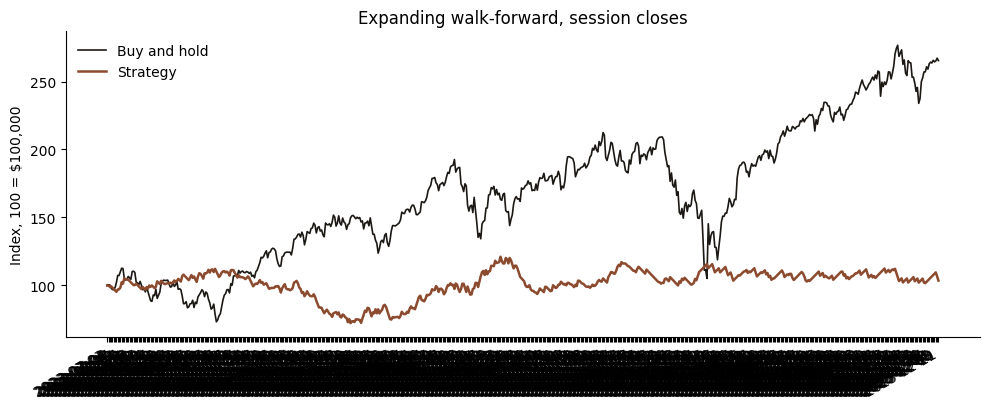

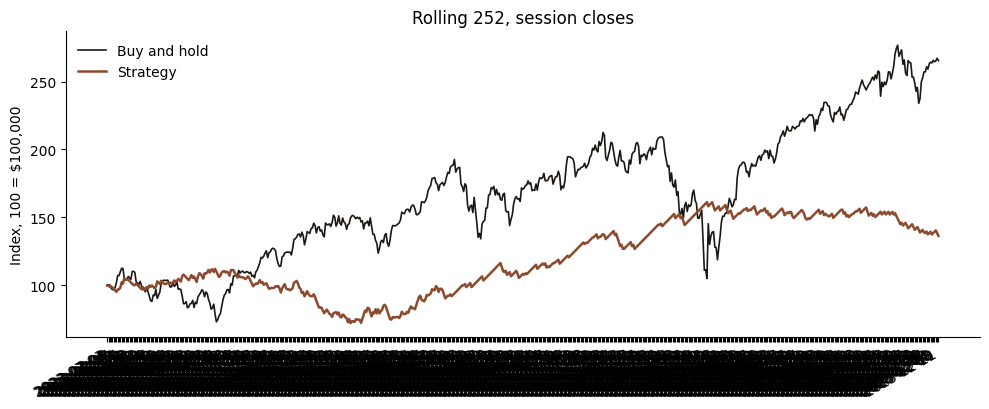

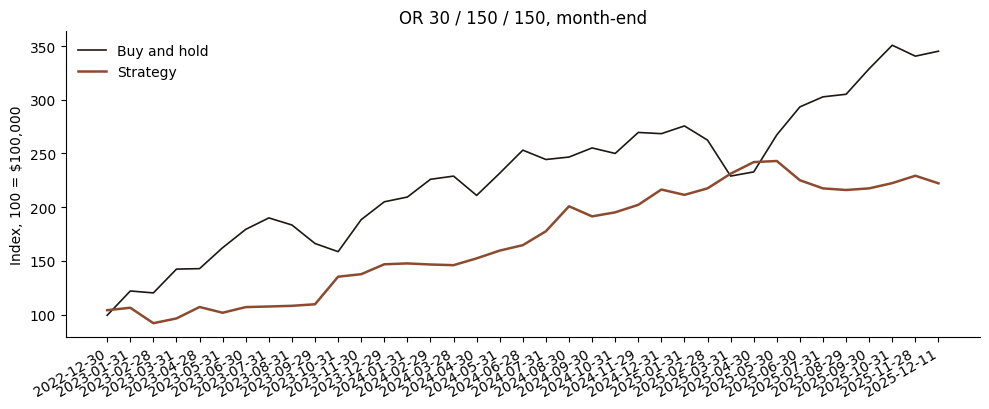

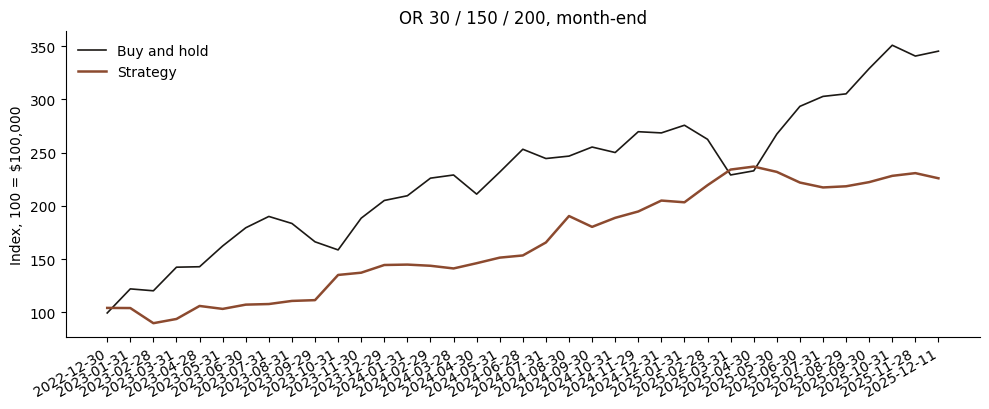

In [6]:
def plot_equity(xs, strat, hold, title):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    base = 100_000
    ax.plot(xs, [v / base * 100 for v in hold], color="#1c1915", lw=1.2, label="Buy and hold")
    ax.plot(xs, [v / base * 100 for v in strat], color="#8c4a2f", lw=1.8, label="Strategy")
    ax.set_title(title)
    ax.set_ylabel("Index, 100 = $100,000")
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.autofmt_xdate()
    fig.tight_layout()
    display(fig)
    plt.close(fig)

def month_path(g):
    return [r["end"] for r in g["monthly"]], [r["end_equity"] for r in g["monthly"]], [r["bh_end_equity"] for r in g["monthly"]]

wf = RES["wf_expanding"]["equity"]
plot_equity([r["d"] for r in wf], [r["eq"] for r in wf], [r["bh"] for r in wf], "Expanding walk-forward, session closes")
wf = RES["wf_rolling"]["equity"]
plot_equity([r["d"] for r in wf], [r["eq"] for r in wf], [r["bh"] for r in wf], "Rolling 252, session closes")
for spec, title in (
    ((30, 150, 150), "OR 30 / 150 / 150, month-end"),
    ((30, 150, 200), "OR 30 / 150 / 200, month-end"),
):
    xs, eq, bh = month_path(cell(*spec))
    plot_equity(xs, eq, bh, title)


## Return attribution

Strategy and buy-and-hold returns use equity at the start of the period as the denominator, so they compound. Difference is strategy minus buy-and-hold, in percentage points. Sharpe is omitted under 20 sessions. Volatility is annualized and omitted under 5.

The four blocks are the expanding book, the rolling book, and the two cells above. Quarter and month for every one of the 64 cells are in the workbook written at the end.


In [7]:
ATTR_COLS = [
    "label", "year", "quarter", "month", "start", "end",
    "strategy_return_pct", "bh_return_pct", "diff_pp",
    "start_equity", "end_equity", "bh_start_equity", "bh_end_equity",
    "net_usd", "trades", "win_rate", "max_dd_pct", "vol_ann_pct", "sharpe", "n_days",
]

def attr_frame(rows):
    df = pd.DataFrame(rows)[ATTR_COLS].copy()
    df["win_rate_pct"] = (df["win_rate"] * 100).round(1)
    return df

def show_block(title, block):
    display(Markdown(f"### {title}"))
    for period in ("annual", "quarterly", "monthly"):
        display(Markdown(f"**{period}**"))
        display(attr_frame(block[period]))

show_block("Expanding walk-forward", RES["wf_expanding"])
show_block("Rolling 252 sessions", RES["wf_rolling"])
show_block("OR 30 / target 150 / stop 150, full sample", cell(30, 150, 150))
show_block("OR 30 / target 150 / stop 200, full sample", cell(30, 150, 200))


### Expanding walk-forward

**annual**

,label,year,quarter,month,start,end,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,bh_start_equity,bh_end_equity,net_usd,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,n_days,win_rate_pct
0,2023,2023,3,7,2023-07-03,2023-12-29,-0.9100,25.19,-26.10,"100,000.00","99,088.50","100,000.00","125,190.50",-911.50,127,0.4488,13.10,24.12,0.0450,129,44.90
1,2024,2024,1,1,2024-01-02,2024-12-31,11.60,50.68,-39.08,"99,088.50","110,586.00","125,190.50","188,640.50","11,497.50",255,0.4588,30.20,34.50,0.4810,259,45.90
2,2025,2025,1,1,2025-01-02,2025-12-11,-6.5900,40.70,-47.28,"110,586.00","103,301.50","188,640.50","265,410.50","-7,284.50",241,0.5892,14.70,23.29,-0.1840,245,58.90


**quarterly**

,label,year,quarter,month,start,end,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,bh_start_equity,bh_end_equity,net_usd,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,n_days,win_rate_pct
0,2023 Q3,2023,3,7,2023-07-03,2023-09-29,7.3300,-13.63,20.96,"100,000.00","107,327.00","100,000.00","86,370.50","7,327.00",64,0.4219,8.1600,23.09,1.3000,65,42.20
1,2023 Q4,2023,4,10,2023-10-02,2023-12-29,-7.6800,44.95,-52.62,"107,327.00","99,088.50","86,370.50","125,190.50","-8,238.50",63,0.4762,13.10,25.17,-1.1250,64,47.60
2,2024 Q1,2024,1,1,2024-01-02,2024-03-28,-24.75,19.11,-43.86,"99,088.50","74,564.00","125,190.50","149,120.50","-24,524.50",61,0.4098,30.20,32.45,-3.3370,63,41.00
3,2024 Q2,2024,2,4,2024-04-01,2024-06-28,24.98,16.21,8.7700,"74,564.00","93,186.50","149,120.50","173,290.50","18,622.50",65,0.5385,12.78,39.63,2.3800,65,53.80
4,2024 Q3,2024,3,7,2024-07-01,2024-09-30,3.9500,1.2000,2.7500,"93,186.50","96,863.50","173,290.50","175,365.50","3,677.00",64,0.4844,19.85,39.12,0.5690,66,48.40
5,2024 Q4,2024,4,10,2024-10-01,2024-12-31,14.17,7.5700,6.6000,"96,863.50","110,586.00","175,365.50","188,640.50","13,722.50",65,0.4000,5.1100,23.71,2.2840,65,40.00
6,2025 Q1,2025,1,1,2025-01-02,2025-03-31,-0.9800,-20.93,19.95,"110,586.00","109,506.00","188,640.50","149,155.50","-1,080.00",60,0.3000,14.70,22.88,-0.0600,63,30.00
7,2025 Q2,2025,2,4,2025-04-01,2025-06-30,-0.5500,43.19,-43.74,"109,506.00","108,907.50","149,155.50","213,580.50",-598.50,63,0.7143,10.59,23.61,0.0260,64,71.40
8,2025 Q3,2025,3,7,2025-07-01,2025-09-30,-2.2000,16.61,-18.81,"108,907.50","106,515.50","213,580.50","249,065.50","-2,392.00",66,0.6515,6.4700,22.56,-0.2640,66,65.10
9,2025 Q4,2025,4,10,2025-10-01,2025-12-11,-3.0200,6.5600,-9.5800,"106,515.50","103,301.50","249,065.50","265,410.50","-3,214.00",52,0.6923,9.6000,24.93,-0.4720,52,69.20


...

,label,year,quarter,month,start,end,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,bh_start_equity,bh_end_equity,net_usd,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,n_days,win_rate_pct
0,2022,2022,4,12,2022-12-27,2022-12-30,4.1000,-0.6600,4.7600,"100,000.00","104,097.00","100,000.00","99,340.50","4,097.00",4,0.7500,0.2900,NaN,NaN,4,75.00
1,2023,2023,1,1,2023-01-03,2023-12-29,38.72,106.36,-67.64,"104,097.00","144,399.50","99,340.50","204,995.50","40,302.50",255,0.5373,21.42,31.60,1.1740,257,53.70
2,2024,2024,1,1,2024-01-02,2024-12-31,41.90,30.95,10.95,"144,399.50","204,908.50","204,995.50","268,445.50","60,509.00",258,0.5620,11.35,21.77,1.6740,259,56.20
3,2025,2025,1,1,2025-01-02,2025-12-11,10.21,28.60,-18.39,"204,908.50","225,835.00","268,445.50","345,220.50","20,926.50",243,0.5514,12.93,18.60,0.6310,245,55.10


**quarterly**

,label,year,quarter,month,start,end,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,bh_start_equity,bh_end_equity,net_usd,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,n_days,win_rate_pct
0,2022 Q4,2022,4,12,2022-12-27,2022-12-30,4.1000,-0.6600,4.7600,"100,000.00","104,097.00","100,000.00","99,340.50","4,097.00",4,0.7500,0.2900,NaN,NaN,4,75.00
1,2023 Q1,2023,1,1,2023-01-03,2023-03-31,-9.9600,43.29,-53.26,"104,097.00","93,724.00","99,340.50","142,345.50","-10,373.00",64,0.5156,21.42,39.91,-0.8380,64,51.60
2,2023 Q2,2023,2,4,2023-04-03,2023-06-30,14.36,26.00,-11.64,"93,724.00","107,180.50","142,345.50","179,355.50","13,456.50",63,0.5238,9.3500,29.60,1.9320,64,52.40
3,2023 Q3,2023,3,7,2023-07-03,2023-09-29,3.9300,-7.3500,11.28,"107,180.50","111,397.50","179,355.50","166,175.50","4,217.00",64,0.5000,9.5400,30.52,0.6410,65,50.00
4,2023 Q4,2023,4,10,2023-10-02,2023-12-29,29.63,23.36,6.2600,"111,397.50","144,399.50","166,175.50","204,995.50","33,002.00",64,0.6094,4.3900,24.51,4.2980,64,60.90
5,2024 Q1,2024,1,1,2024-01-02,2024-03-28,-2.2400,11.67,-13.91,"144,399.50","141,166.00","204,995.50","228,925.50","-3,233.50",63,0.5079,7.0000,20.62,-0.3380,63,50.80
6,2024 Q2,2024,2,4,2024-04-01,2024-06-28,8.6400,10.56,-1.9200,"141,166.00","153,363.50","228,925.50","253,095.50","12,197.50",65,0.5385,9.1800,24.17,1.4490,65,53.80
7,2024 Q3,2024,3,7,2024-07-01,2024-09-30,17.50,0.8200,16.68,"153,363.50","180,206.00","253,095.50","255,170.50","26,842.50",65,0.6000,10.52,23.48,2.7420,66,60.00
8,2024 Q4,2024,4,10,2024-10-01,2024-12-31,13.71,5.2000,8.5100,"180,206.00","204,908.50","255,170.50","268,445.50","24,702.50",65,0.6000,4.4000,18.52,2.7830,65,60.00
9,2025 Q1,2025,1,1,2025-01-02,2025-03-31,14.21,-14.71,28.92,"204,908.50","234,019.50","268,445.50","228,960.50","29,111.00",62,0.6129,6.0900,20.41,2.7070,63,61.30


**monthly**

,label,year,quarter,month,start,end,strategy_return_pct,bh_return_pct,diff_pp,start_equity,end_equity,bh_start_equity,bh_end_equity,net_usd,trades,win_rate,max_dd_pct,vol_ann_pct,sharpe,n_days,win_rate_pct
0,Dec 2022,2022,4,12,2022-12-27,2022-12-30,4.1000,-0.6600,4.7600,"100,000.00","104,097.00","100,000.00","99,340.50","4,097.00",4,0.7500,0.2900,NaN,NaN,4,75.00
1,Jan 2023,2023,1,1,2023-01-03,2023-01-31,-0.1200,22.78,-22.90,"104,097.00","103,972.50","99,340.50","121,970.50",-124.50,21,0.5238,7.8900,36.57,0.1360,21,52.40
2,Feb 2023,2023,1,2,2023-02-01,2023-02-28,-13.68,-1.4700,-12.21,"103,972.50","89,752.50","121,970.50","120,180.50","-14,220.00",20,0.4000,16.31,40.00,-4.4240,20,40.00
3,Mar 2023,2023,1,3,2023-03-01,2023-03-31,4.4200,18.44,-14.02,"89,752.50","93,724.00","120,180.50","142,345.50","3,971.50",23,0.6087,10.16,43.00,1.3110,23,60.90
4,Apr 2023,2023,2,4,2023-04-03,2023-04-28,13.03,0.3000,12.73,"93,724.00","105,933.50","142,345.50","142,765.50","12,209.50",19,0.6316,3.1300,26.92,NaN,19,63.20
5,May 2023,2023,2,5,2023-05-01,2023-05-31,-2.6000,13.67,-16.28,"105,933.50","103,174.50","142,765.50","162,285.50","-2,759.00",22,0.4545,9.3500,28.80,-0.8660,23,45.40
6,Jun 2023,2023,2,6,2023-06-01,2023-06-30,3.8800,10.52,-6.6400,"103,174.50","107,180.50","162,285.50","179,355.50","4,006.00",22,0.5000,7.3100,32.64,1.4940,22,50.00
7,Jul 2023,2023,3,7,2023-07-03,2023-07-31,0.5200,5.9300,-5.4100,"107,180.50","107,740.50","179,355.50","189,995.50",560.00,20,0.4500,9.5400,27.13,0.3590,21,45.00
8,Aug 2023,2023,3,8,2023-08-01,2023-08-31,2.7200,-3.4700,6.1800,"107,740.50","110,667.00","189,995.50","183,405.50","2,926.50",23,0.5652,5.8000,34.31,1.0210,23,56.50
9,Sep 2023,2023,3,9,2023-09-01,2023-09-29,0.6600,-9.3900,10.05,"110,667.00","111,397.50","183,405.50","166,175.50",730.50,21,0.4762,5.6400,30.80,0.4030,21,47.60


## Every cell

Full sample resets at the first session. The holdout resets on 2024-07-01 and runs through the last session. Both are reported for every cell. Neither is the walk-forward. Sorted by full-sample points, which is the order on the note.


In [8]:
grid_rows = []
for g in RES["grid"]:
    grid_rows.append({
        "or": g["or"],
        "target": g["tp"],
        "stop": g["sl"],
        "full_points": g["full"]["net_points"],
        "full_return_pct": g["full"]["return_pct"],
        "full_sharpe": g["full"]["sharpe"],
        "full_dd_pct": g["full"]["max_dd_pct"],
        "full_dd_usd": g["full"]["max_dd_usd"],
        "full_win_pct": round(g["full"]["win_rate"] * 100, 1),
        "full_trades": g["full"]["trades"],
        "full_end_equity": g["full"]["end_equity"],
        "holdout_points": g["oos"]["net_points"],
        "holdout_return_pct": g["oos"]["return_pct"],
        "holdout_sharpe": g["oos"]["sharpe"],
        "holdout_dd_pct": g["oos"]["max_dd_pct"],
        "holdout_win_pct": round(g["oos"]["win_rate"] * 100, 1),
        "train_sharpe": g["is"]["sharpe"],
        "train_points": g["is"]["net_points"],
        "train_return_pct": g["is"]["return_pct"],
        "train_dd_pct": g["is"]["max_dd_pct"],
        "gross_points": g["full"]["gross_net_points"],
        "stress_points": g["full"]["stress_net_points"],
        "long_points": g["full"]["long_points"],
        "short_points": g["full"]["short_points"],
        "profit_factor": g["full"]["profit_factor"],
    })
grid = pd.DataFrame(grid_rows).sort_values("full_points", ascending=False).reset_index(drop=True)
display(grid)


,or,target,stop,full_points,full_return_pct,full_sharpe,full_dd_pct,full_dd_usd,full_win_pct,full_trades,full_end_equity,holdout_points,holdout_return_pct,holdout_sharpe,holdout_dd_pct,holdout_win_pct,train_sharpe,train_points,train_return_pct,train_dd_pct,gross_points,stress_points,long_points,short_points,profit_factor
0,30,150,200,"6,291.75",125.84,1.2130,21.42,"23,725.50",55.10,760,"225,835.00","3,623.58",72.47,1.5080,16.58,56.80,1.1070,"2,668.18",53.36,21.42,"6,796.25","5,825.25","5,482.07",809.68,1.1840
1,30,150,150,"6,111.00",122.22,1.2490,20.14,"22,500.50",53.60,760,"222,220.00","2,879.83",57.60,1.2960,19.90,54.20,1.3180,"3,231.18",64.62,20.14,"6,616.75","5,643.25","5,159.07",951.93,1.1830
2,30,200,200,"5,358.75",107.18,1.0170,30.26,"33,878.00",53.00,760,"207,175.00","3,189.08",63.78,1.3190,19.58,53.60,0.8950,"2,169.68",43.39,30.26,"5,884.25","4,871.25","5,089.32",269.43,1.1500
3,30,200,150,"5,278.00",105.56,1.0570,27.66,"31,243.00",51.40,760,"205,560.00","2,498.33",49.97,1.1200,22.00,50.90,1.1060,"2,779.68",55.59,27.66,"5,804.50","4,789.50","4,866.32",411.67,1.1530
4,30,100,150,"5,120.75",102.42,1.1700,16.54,"18,032.50",57.80,760,"202,415.00","2,901.58",58.03,1.5320,17.60,60.10,1.0450,"2,219.18",44.38,16.54,"5,592.75","4,686.75","4,303.82",816.93,1.1680
5,30,50,150,"4,918.00",98.36,1.3990,20.05,"22,000.50",72.00,760,"198,360.00","2,787.08",55.74,1.8710,8.9900,74.50,1.2190,"2,130.93",42.62,20.05,"5,340.75","4,533.25","3,987.83",930.18,1.2340
6,60,150,150,"4,823.55",96.47,1.1960,23.16,"36,871.00",53.20,742,"196,471.00","1,654.18",33.08,0.8530,26.54,52.00,1.5200,"3,169.38",63.39,23.16,"5,329.25","4,354.95","5,567.42",-743.87,1.1690
7,5,150,200,"4,605.08",92.10,0.7590,41.68,"49,812.50",53.50,763,"192,101.50","5,388.63",107.77,1.7400,24.42,56.80,-0.0750,-783.55,-15.67,41.68,"5,098.00","4,150.30","4,996.25",-391.17,1.1150
8,30,100,200,"4,502.75",90.05,0.9920,20.07,"21,743.00",59.10,760,"190,055.00","2,959.83",59.20,1.4520,19.62,62.20,0.7570,"1,542.93",30.86,20.07,"4,973.25","4,070.25","4,031.83",470.93,1.1420
9,30,150,100,"4,446.75",88.94,1.0000,16.70,"22,455.50",48.30,760,"188,935.00","2,664.83",53.30,1.3520,12.92,47.70,0.8450,"1,781.93",35.64,16.70,"4,955.25","3,976.25","4,571.07",-124.33,1.1380


## Rules, so the numbers can be audited


In [9]:
for i, rule in enumerate(meta["rules"], 1):
    print(f"{i}. {rule}\n")

diag = RES["diagnostics"]
print(f"bars that traded both stop and target, booked as stops: {diag['same_bar_stop_and_target']:,}")
print(f"overnight gaps of 200 points or more: {len(diag['large_rth_gaps'])}")
by_or = []
for or_, info in diag["by_or"].items():
    status = info["status"]
    by_or.append({
        "or": int(or_),
        "trades": status.get("trade", 0),
        "no_break": status.get("flat", 0),
        "ambiguous": status.get("ambiguous", 0),
        "incomplete": status.get("incomplete_or", 0),
        "zero_width": status.get("zero_width", 0),
        "avg_width": info["avg_width"],
        "width_samples": info["width_samples"],
    })
display(pd.DataFrame(by_or).sort_values("or"))
display(pd.DataFrame(diag["large_rth_gaps"]))


1. Session is RTH, 09:30–16:00 America/New_York. Bars are minute stamps. The 16:00 stamp is the closing bar (volume spike) and is flatten-only — no new entries.

2. Opening range is the first N minute bars starting 09:30. N is 5, 15, 30, or 60. A missing minute inside the range skips that day for that N.

3. After the range completes, the first touch of the range high is a long and the first touch of the range low is a short. One trade a day. If one bar trades through both sides, the day is skipped.

4. A stop order fills at the range level, or at the open if the bar gaps through. Target and stop are measured in index points from that signal price.

5. Stops and targets are live from the next bar. On the breakout bar itself, a target is filled when the bar trades through it and does not also trade through the stop. If that bar reaches both, the stop is assumed. The pre-breakout wick is not a stop. Gap-through entries are managed on the entry bar from the open, and a bar that opens thro

,or,trades,no_break,ambiguous,incomplete,zero_width,avg_width,width_samples
0,5,763,0,1,1,0,50.47,764
1,15,764,0,0,1,0,80.35,764
2,30,760,3,0,2,0,106.27,763
3,60,742,21,0,2,0,142.85,763


,from,to,points
0,2023-02-01,2023-02-02,254.50
1,2023-02-02,2023-02-03,-290.00
2,2023-02-15,2023-02-16,-213.25
3,2023-02-23,2023-02-24,-212.50
4,2023-05-24,2023-05-25,304.75
5,2023-07-26,2023-07-27,217.00
6,2023-11-13,2023-11-14,267.00
7,2024-02-12,2024-02-13,-343.25
8,2024-02-21,2024-02-22,349.50
9,2024-03-15,2024-03-18,213.75


## Workbook

`data/nq_orb_results.xlsx` holds the verdict, both fold tables, the 64-cell grid, the reconciliation, and quarter / year / month attribution for the walk-forwards and for every cell.


In [10]:
def stack_cells(period):
    frames = []
    for g in RES["grid"]:
        df = attr_frame(g[period])
        df.insert(0, "stop", g["sl"])
        df.insert(0, "target", g["tp"])
        df.insert(0, "or", g["or"])
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

out = ROOT / "data" / "nq_orb_results.xlsx"
cover = pd.DataFrame({"text": verdict.split("\n\n")})
with pd.ExcelWriter(out, engine="openpyxl") as xw:
    cover.to_excel(xw, sheet_name="Verdict", index=False)
    kpis.to_excel(xw, sheet_name="Verdict_kpis", index=False)
    grid.to_excel(xw, sheet_name="Grid", index=False)
    audit.to_excel(xw, sheet_name="Reconciliation", index=False)
    folds_frame(RES["wf_expanding"]).to_excel(xw, sheet_name="Folds_expanding", index=False)
    folds_frame(RES["wf_rolling"]).to_excel(xw, sheet_name="Folds_rolling", index=False)
    attr_frame(RES["wf_expanding"]["annual"]).to_excel(xw, sheet_name="Annual_expanding", index=False)
    attr_frame(RES["wf_expanding"]["quarterly"]).to_excel(xw, sheet_name="Quarter_expanding", index=False)
    attr_frame(RES["wf_expanding"]["monthly"]).to_excel(xw, sheet_name="Month_expanding", index=False)
    attr_frame(RES["wf_rolling"]["annual"]).to_excel(xw, sheet_name="Annual_rolling", index=False)
    attr_frame(RES["wf_rolling"]["quarterly"]).to_excel(xw, sheet_name="Quarter_rolling", index=False)
    attr_frame(RES["wf_rolling"]["monthly"]).to_excel(xw, sheet_name="Month_rolling", index=False)
    stack_cells("annual").to_excel(xw, sheet_name="Annual_all_cells", index=False)
    stack_cells("quarterly").to_excel(xw, sheet_name="Quarter_all_cells", index=False)
    stack_cells("monthly").to_excel(xw, sheet_name="Month_all_cells", index=False)
    pd.DataFrame(by_or).to_excel(xw, sheet_name="Diagnostics", index=False)
    pd.DataFrame(diag["large_rth_gaps"]).to_excel(xw, sheet_name="Large_gaps", index=False)
    pd.DataFrame({"rule": meta["rules"]}).to_excel(xw, sheet_name="Rules", index=False)
print(out, out.stat().st_size)


/tmp/nq-opening-range-breakout/data/nq_orb_results.xlsx 460799
